# Name - Suhani Joshi
# Batch - C_C2
# Roll no -21

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')


In [ ]:
df=pd.read_csv('diabetes.csv')
print("Shape:", df.shape)

Shape: (767, 9)


In [ ]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.tail()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
762,9,89,62,0,0,22.5,0.142,33,0
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [ ]:
df.shape

(767, 9)

In [ ]:
df.columns.tolist()

['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age',
 'Outcome']

In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000
mean,3.848761,120.930900,69.104302,20.522816,79.903520,31.994654,0.472081,33.254237,0.349413
std,3.370207,31.977581,19.368410,15.958143,115.283105,7.889095,0.331496,11.762079,0.477096
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243500,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,32.000000,32.000000,0.374000,29.000000,0.000000
75%,6.000000,140.500000,80.000000,32.000000,127.500000,36.600000,0.626500,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 767 entries, 0 to 766
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               767 non-null    int64  
 1   Glucose                   767 non-null    int64  
 2   BloodPressure             767 non-null    int64  
 3   SkinThickness             767 non-null    int64  
 4   Insulin                   767 non-null    int64  
 5   BMI                       767 non-null    float64
 6   DiabetesPedigreeFunction  767 non-null    float64
 7   Age                       767 non-null    int64  
 8   Outcome                   767 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
missing =  df.isnull().sum()
print( "Missing values:")
print(missing)

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


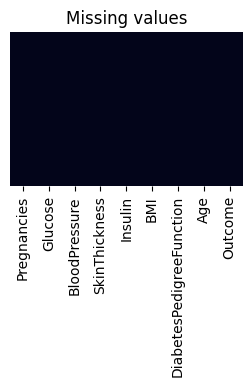

In [ ]:
plt.figure(figsize=(3, 2))

sns.heatmap(df.isnull(),
            cbar= False,
            yticklabels = False
)

plt.title("Missing values")
plt.show()

In [ ]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
if duplicate_count > 0:
    df.drop_duplicates().reset_index(drop=True)
    print("New shape", df.shape)


In [ ]:
print(df["Outcome"].value_counts())

Outcome
0    499
1    268
Name: count, dtype: int64


In [ ]:
target_percentage = (
    df["Outcome"].value_counts(normalize=True).sort_index() * 100
)

print(target_percentage)


Outcome
0    65.05867
1    34.94133
Name: proportion, dtype: float64


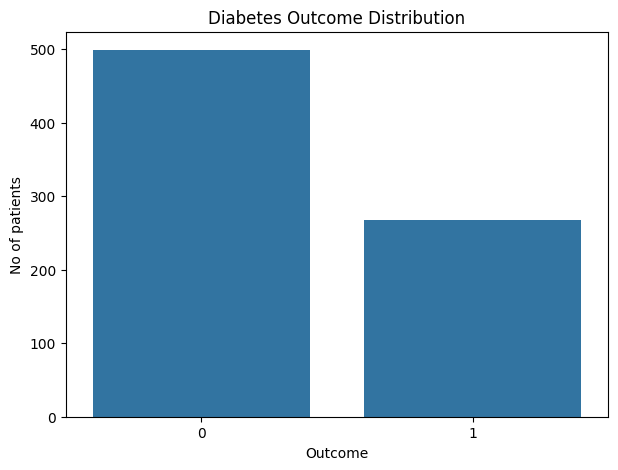

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x= "Outcome"
)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("No of patients")
plt.show()

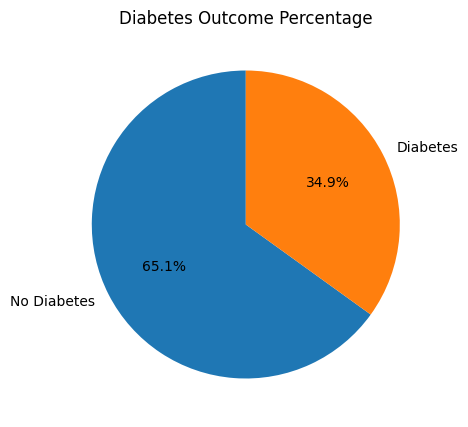

In [ ]:
plt.figure(figsize=(7,5))

plt.pie(
    target_percentage,
    labels=["No Diabetes", "Diabetes"],
    autopct= "%1.1f%%",
    startangle=90,

)

plt.title("Diabetes Outcome Percentage")
plt.show()


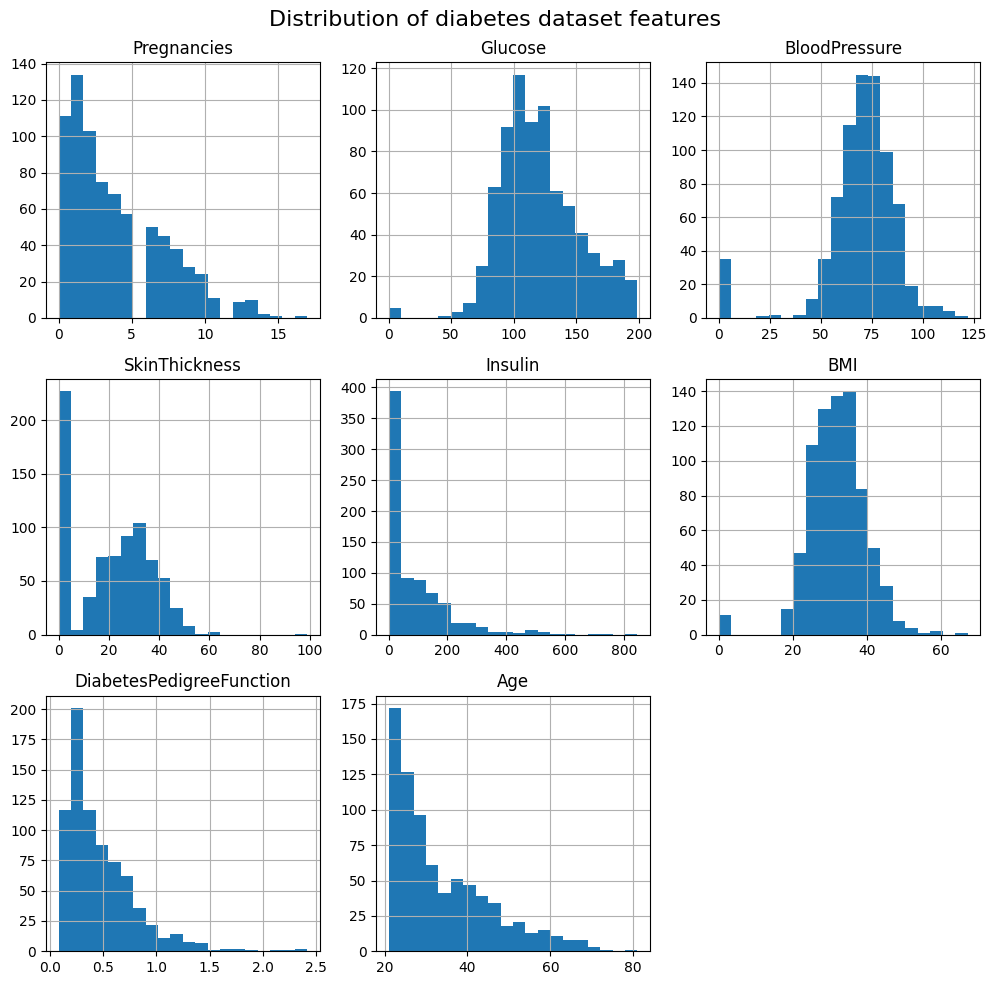

In [ ]:
features = df.drop(columns= "Outcome").columns

df[features].hist(figsize=(10, 10),bins = 20, )

plt.suptitle("Distribution of diabetes dataset features", fontsize=16)

plt.tight_layout()
plt.show()

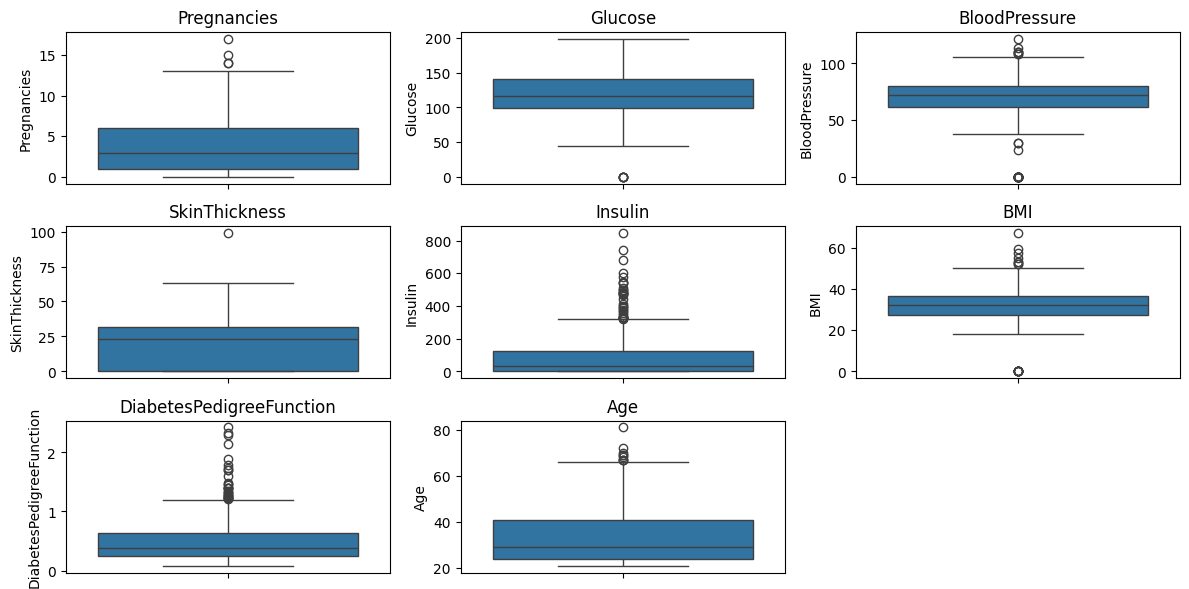

In [ ]:
plt.figure(figsize=(12, 6))

for i, col in enumerate(features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()


In [ ]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

zero_counts = (df[zero_columns] ==0).sum()
print("Zero values")
print(zero_counts)


Zero values
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          373
BMI               11
dtype: int64


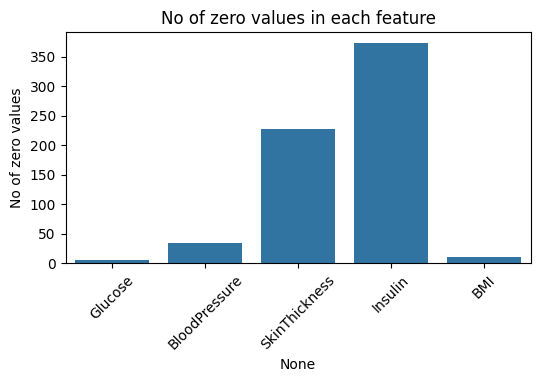

In [ ]:
plt.figure(figsize= (6,3))

sns.barplot(x = zero_counts.index, y = zero_counts.values)

plt.xticks(rotation= 45)
plt.ylabel("No of zero values")
plt.title("No of zero values in each feature")
plt.show()

In [ ]:
df_clean = df.copy()

df_clean[zero_columns] = df_clean[zero_columns].replace(0, np.nan)

print("Misiing values after replacing invalid zeros:")
print(df_clean.isnull().sum())

Misiing values after replacing invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     373
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


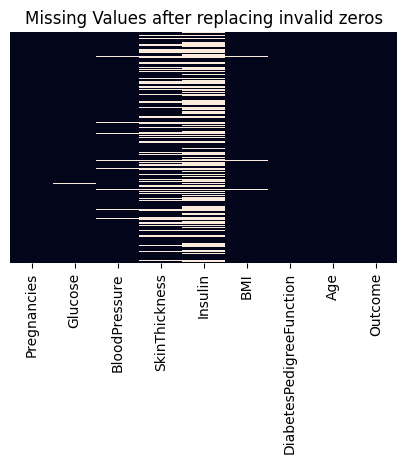

In [ ]:
plt.figure(figsize = (5,3))

sns.heatmap(df_clean.isnull(), cbar=False, yticklabels=False)

plt.title("Missing Values after replacing invalid zeros")
plt.show()

In [ ]:
for col in zero_columns:
     df_clean[col].fillna(df_clean[col].median(), inplace=True)

print("Missing values after replacing with median:")
print(df_clean.isnull().sum())

Missing values after replacing with median:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


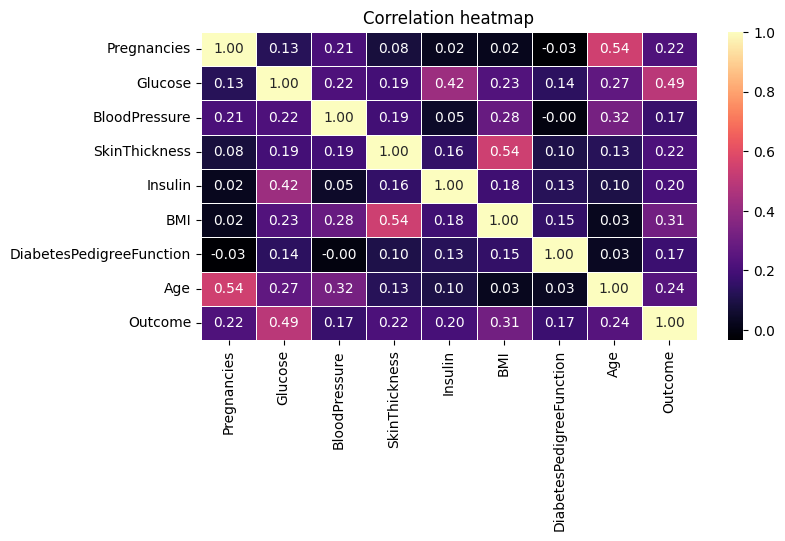

In [ ]:
plt.figure(figsize = (8,4))

correlation = df_clean.corr()

sns.heatmap(correlation, annot=True, fmt=".2f", cmap="magma", linewidths=0.5)
plt.title("Correlation heatmap")
plt.show()

In [ ]:
target_corr = (df_clean.corr()["Outcome"].drop("Outcome").sort_values())
print(target_corr)

BloodPressure               0.165597
DiabetesPedigreeFunction    0.173478
Insulin                     0.203693
SkinThickness               0.215160
Pregnancies                 0.221272
Age                         0.237725
BMI                         0.311880
Glucose                     0.492340
Name: Outcome, dtype: float64


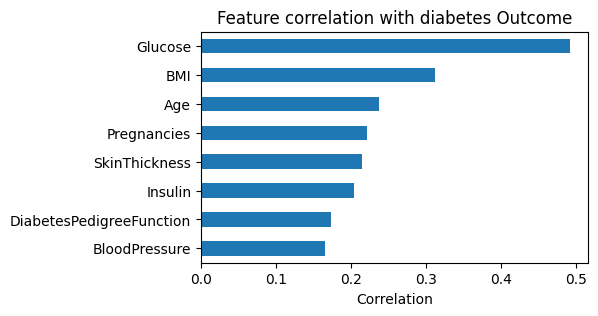

In [ ]:
plt.figure(figsize= (5,3))

target_corr.plot(kind= "barh")

plt.title("Feature correlation with diabetes Outcome")
plt.xlabel("Correlation")
plt.show()

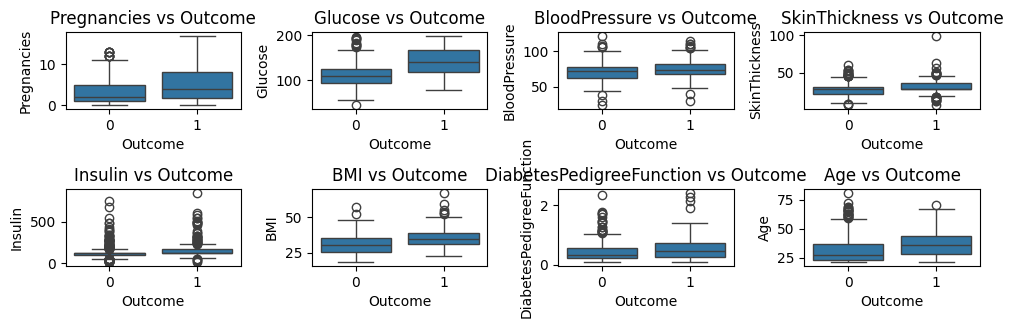

In [ ]:
plt.figure(figsize= (10,6))

for i, col in enumerate (features, 1):
    plt.subplot(4, 4, i)
    sns.boxplot(data = df_clean, x = "Outcome", y= col)
    plt.title(f"{col} vs Outcome")

plt.tight_layout()
plt.show()

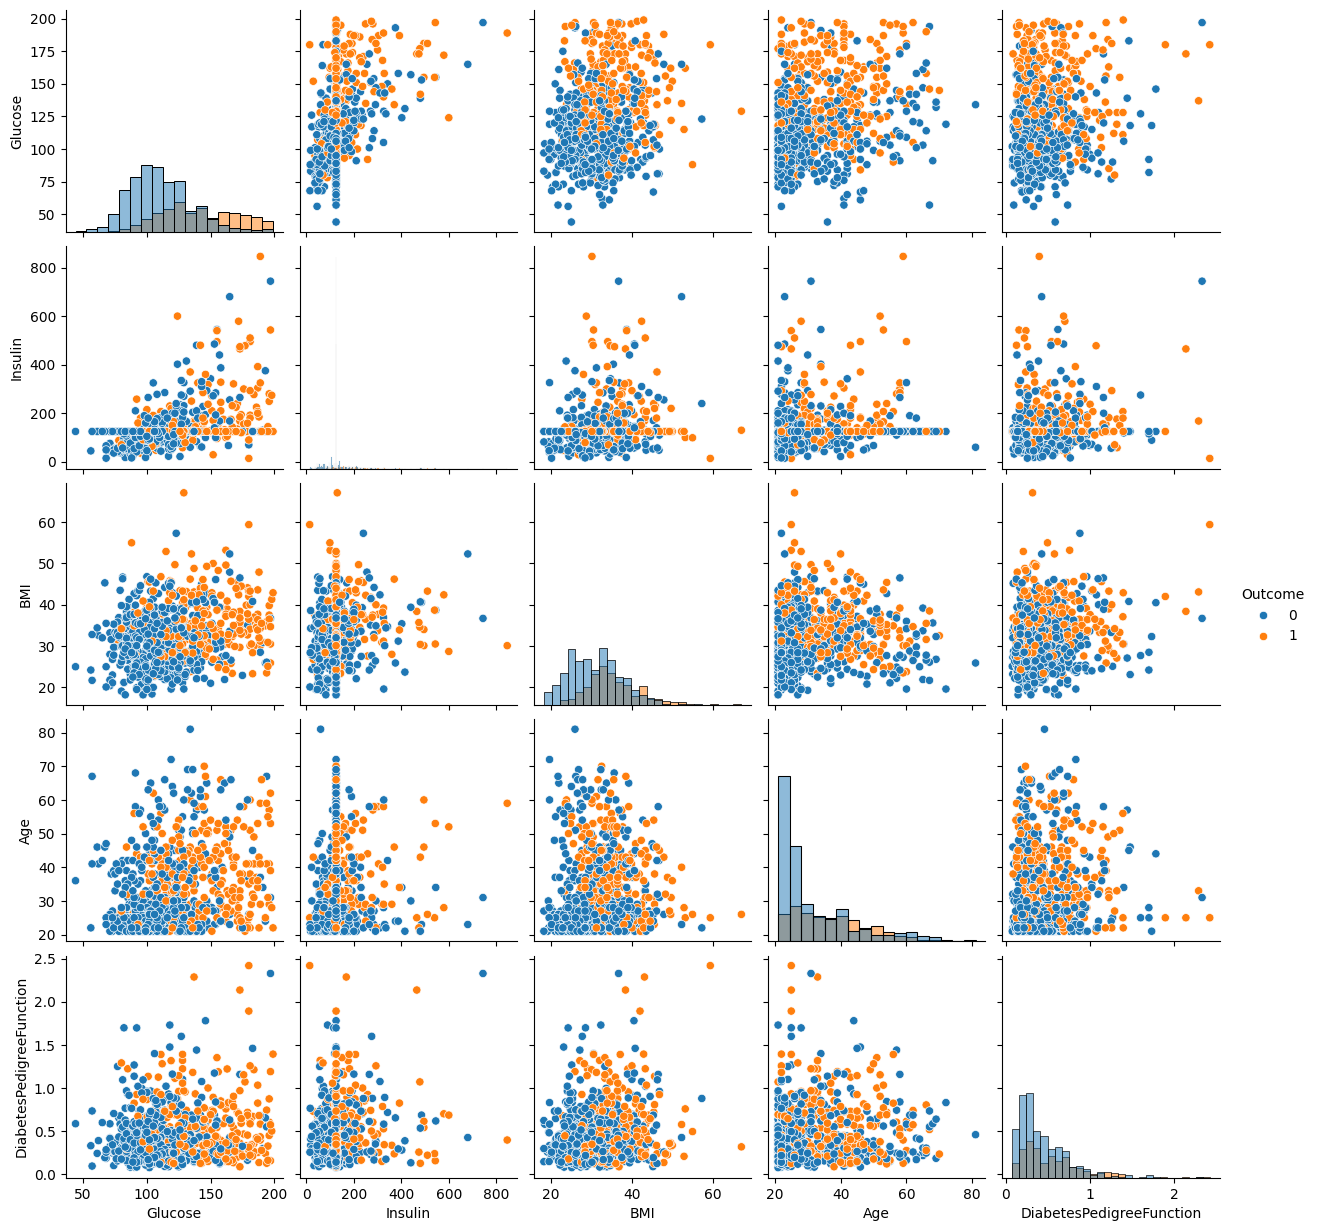

In [ ]:
selected_features = [
    "Glucose",
    "Insulin",
    "BMI",
    "Age",
    "DiabetesPedigreeFunction",
    "Outcome"
]

sns.pairplot(
    df_clean[selected_features],
    hue="Outcome",
    diag_kind="hist"
)

plt.show()


In [ ]:
X = df_clean.drop("Outcome", axis = 1)
y= df_clean["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (767, 8)
y shape: (767,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)

print("Training samples", X_train.shape[0])
print("Testing samples", X_test.shape[0])

Training samples 613
Testing samples 154


In [ ]:
print("Training distribution:")
print(y_train.value_counts(normalize=True))

print("Testing distribution:")
print(y_test.value_counts(normalize=True))

Training distribution:
Outcome
0    0.650897
1    0.349103
Name: proportion, dtype: float64
Testing distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed.")

Scaling completed.


In [ ]:
scaler.fit_transform(X_test)


array([[ 0.86715277,  1.16165312, -0.76879219, ..., -0.70130688,
        -0.46270264,  0.71962209],
       [-0.83763267, -0.71093495, -1.31188392, ..., -0.97873113,
         0.29209272, -1.01768339],
       [-0.55350177,  0.00689048,  0.31739127, ...,  0.47774617,
         0.09238033, -0.56049774],
       ...,
       [-0.55350177, -1.24150157, -1.85497566, ..., -0.54872355,
         3.66370777, -0.65193487],
       [ 0.01476005,  1.94189814,  0.49842185, ...,  0.63032951,
        -0.55081104, -0.10331208],
       [-0.83763267, -1.58480938,  0.49842185, ...,  0.10322344,
        -0.08677343, -1.01768339]])

In [ ]:
scaler.transform(X_test)

array([[ 0.86715277,  1.16165312, -0.76879219, ..., -0.70130688,
        -0.46270264,  0.71962209],
       [-0.83763267, -0.71093495, -1.31188392, ..., -0.97873113,
         0.29209272, -1.01768339],
       [-0.55350177,  0.00689048,  0.31739127, ...,  0.47774617,
         0.09238033, -0.56049774],
       ...,
       [-0.55350177, -1.24150157, -1.85497566, ..., -0.54872355,
         3.66370777, -0.65193487],
       [ 0.01476005,  1.94189814,  0.49842185, ...,  0.63032951,
        -0.55081104, -0.10331208],
       [-0.83763267, -1.58480938,  0.49842185, ...,  0.10322344,
        -0.08677343, -1.01768339]])

In [ ]:
comparsion = pd.DataFrame({
    "Original Mean": X_train.mean(),
    "Original Std": X_train.std(),
    "Scaled Mean": X_train_scaled.mean(axis=0),
    "Scaled Std": X_train_scaled.std(axis=0)
})
display(comparsion)

,Original Mean,Original Std,Scaled Mean,Scaled Std
Pregnancies,3.823817,3.331120,1.738685e-17,1.0
Glucose,121.672104,30.024257,-1.709707e-16,1.0
BloodPressure,72.363785,12.355695,1.043211e-16,1.0
SkinThickness,29.101142,8.915336,-1.796642e-16,1.0
Insulin,137.600326,78.919222,3.622261e-17,1.0
BMI,32.458401,6.793722,2.376203e-16,1.0
DiabetesPedigreeFunction,0.477240,0.328993,-6.664960e-17,1.0
Age,33.536705,11.944207,2.144379e-16,1.0


In [ ]:
Knn = KNeighborsClassifier(n_neighbors=5)

Knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [ ]:
y_pred = Knn.predict(X_test_scaled)

print("Predictions:")
print(y_pred[:20])

Predictions:
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0]


In [ ]:
y_prob = Knn.predict_proba(X_test_scaled)[:,1]

print(y_prob[:20])

[0.6 0.  0.2 0.6 0.  0.2 0.2 0.8 0.  0.6 0.4 0.6 0.  0.  0.  0.6 0.8 0.
 0.8 0.2]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.7532


In [ ]:
precision = precision_score(y_test, y_pred)
print(f"Precision: {precision:.4f}")

Precision: 0.6667


In [ ]:
recall = recall_score(y_test, y_pred)
print(f"Recall: {recall:.4f}")

Recall: 0.5926


In [ ]:
f1 = f1_score(y_test, y_pred)
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.6275


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Diabetes", "Diabetes"]
    )
)


              precision    recall  f1-score   support

 No Diabetes       0.79      0.84      0.82       100
    Diabetes       0.67      0.59      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[84 16]
 [22 32]]


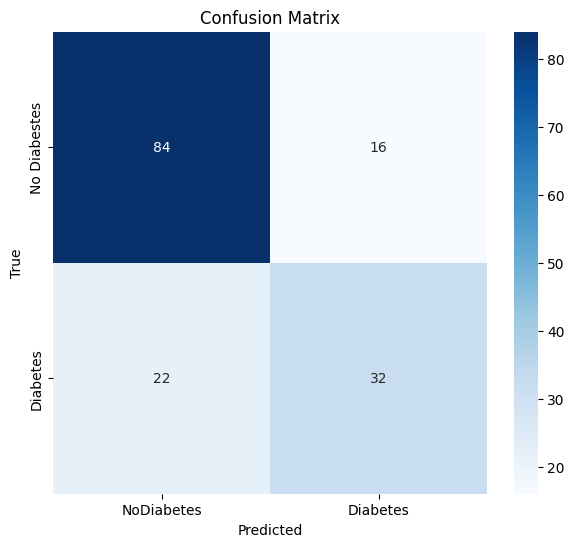

In [ ]:
plt.figure(figsize=(7,6))

sns.heatmap(cm , annot=True, fmt="d", cmap="Blues", xticklabels=["NoDiabetes", "Diabetes"],
            yticklabels=["No Diabestes", "Diabetes"])

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
k_values = range(1, 31)

train_accuracy = []
test_accuracy = []


for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    train_accuracy.append(model.score(X_train_scaled, y_train))
    test_accuracy.append(model.score(X_test_scaled, y_test))

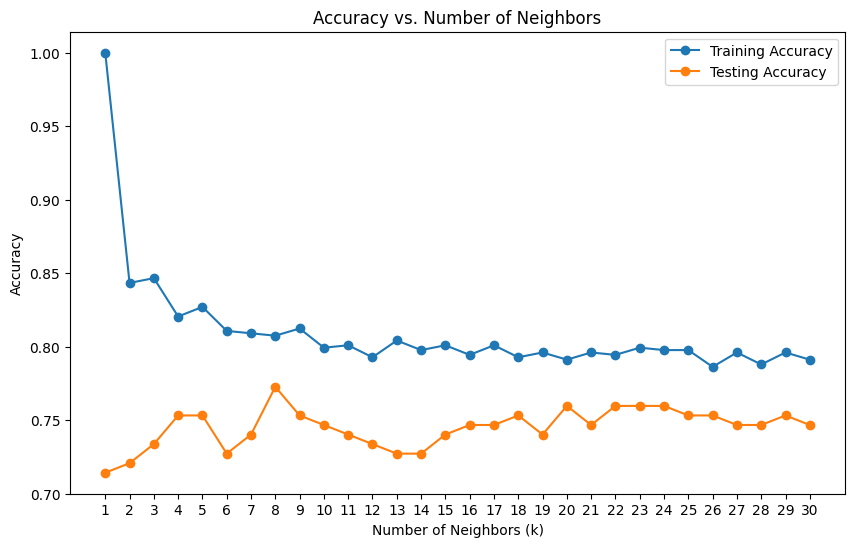

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(k_values, train_accuracy,marker = "o", label="Training Accuracy")
plt.plot(k_values, test_accuracy, marker = "o", label="Testing Accuracy")

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. Number of Neighbors")
plt.xticks(k_values)
plt.legend()
plt.show()

In [ ]:
best_k_accuracy = k_values[np.argmax(test_accuracy)]
best_accuracy = max(test_accuracy)

print(f"Best k value",best_k_accuracy)
print(f"Best accuracy" , best_accuracy)

Best k value 8
Best accuracy 0.7727272727272727


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring="accuracy")
    cv_scores.append(scores.mean())

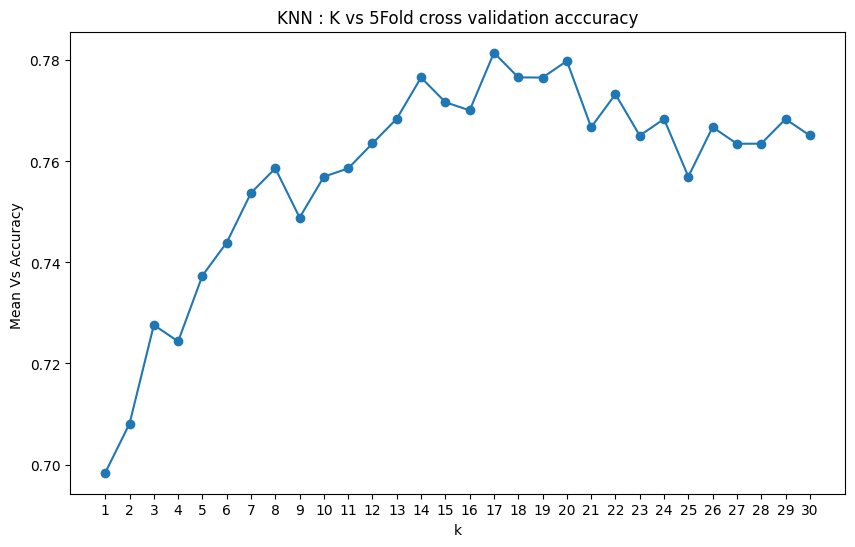

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(k_values, cv_scores, marker="o")

plt.xlabel("k")
plt.ylabel("Mean Vs Accuracy ")
plt.title("KNN : K vs 5Fold cross validation acccuracy")

plt.xticks(range(1,31))

plt.show()

In [ ]:
best_k_cv = np.argmax(cv_scores) + 1

print("Best K based on cross validation:", best_k_cv)
print("Best accuracy based on cross validation:", max(cv_scores))


Best K based on cross validation: 17
Best accuracy based on cross validation: 0.7815140610422497


In [ ]:
param_grid ={ "n_neighbors" :list(range(3,31,2)), "weights": ["uniform", "distance"],
             "metric": ["euclidean", "manhattan", "minkowski"],
              "p":[1,2]

              }

In [ ]:
grid_search = GridSearchCV(estimator = KNeighborsClassifier(), param_grid=param_grid, cv=5, scoring="accuracy", n_jobs = -1)

grid_search.fit(X_train_scaled, y_train)

print("Grid seach completed")

Grid seach completed


In [ ]:
print("Best parameters:")
print(grid_search.best_params_)



Best parameters:
{'metric': 'euclidean', 'n_neighbors': 23, 'p': 1, 'weights': 'uniform'}


In [ ]:
print("Best cross validation accuracy:", grid_search.best_score_)

Best cross validation accuracy: 0.7732107157137145


In [ ]:
best_knn = grid_search.best_estimator_
print(best_knn)

KNeighborsClassifier(metric='euclidean', n_neighbors=23, p=1)
